In [2]:

%pip install -q "transformers==4.48.3" "tokenizers==0.21.0" datasets evaluate rouge_score nltk sumy accelerate


In [3]:

import torch
import transformers
import datasets
import evaluate
import nltk
import sumy

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("We will use the CPU for now.")

print("Environment setup successful!")


PyTorch version: 2.11.0+cu130
Transformers version: 4.48.3
GPU available: True
GPU name: Tesla T4
Environment setup successful!


In [4]:

from datasets import load_dataset

# Download the CNN/DailyMail dataset
dataset = load_dataset("abisee/cnn_dailymail", "3.0.0")

print("Dataset loaded successfully!")
print(dataset)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 287113
    })
    validation: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 13368
    })
    test: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 11490
    })
})


In [5]:

# Select a manageable subset for this project
train_data = dataset["train"].select(range(500))
test_data = dataset["test"].select(range(100))

print("Training articles:", len(train_data))
print("Testing articles:", len(test_data))
print("Dataset columns:", train_data.column_names)


Training articles: 500
Testing articles: 100
Dataset columns: ['article', 'highlights', 'id']


In [6]:

# Get the first test example
sample = test_data[0]

print("ARTICLE:")
print(sample["article"][:2000])

print("\n" + "=" * 60)
print("REFERENCE SUMMARY:")
print(sample["highlights"])


ARTICLE:
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body. But Palestinian Foreign Minister Riad al-Malki, speaking at Wednesday's cer

In [7]:

import torch
from transformers import pipeline

summarizer = pipeline(
    "summarization",
    model="facebook/bart-large-cnn",
    device=-1
)

print("BART summarization model loaded successfully!")


Device set to use cpu


BART summarization model loaded successfully!


In [8]:

# Select one test article
article = test_data[0]["article"]

# Generate a summary
output = summarizer(
    article,
    max_length=100,
    min_length=25,
    do_sample=False,
    truncation=True
)

generated_summary = output[0]["summary_text"]

print("GENERATED SUMMARY:")
print(generated_summary)

print("\n" + "=" * 60)
print("REFERENCE SUMMARY:")
print(test_data[0]["highlights"])


Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


GENERATED SUMMARY:
Palestinian Authority becomes 123rd member of the International Criminal Court. The move gives the court jurisdiction over alleged crimes in Palestinian territories. Israel and the United States opposed the Palestinians' efforts to join the body.

REFERENCE SUMMARY:
Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June .
Israel and the United States opposed the move, which could open the door to war crimes investigations against Israelis .


In [9]:

import evaluate

# Load the ROUGE evaluation metric
rouge = evaluate.load("rouge")

# Compare the generated summary with the reference
scores = rouge.compute(
    predictions=[generated_summary],
    references=[test_data[0]["highlights"]]
)

print("ROUGE scores for the first article:")
for metric, score in scores.items():
    print(f"{metric}: {score:.4f}")


ROUGE scores for the first article:
rouge1: 0.5507
rouge2: 0.3881
rougeL: 0.4928
rougeLsum: 0.4928


In [11]:

print("Model maximum input positions:",
      summarizer.model.config.max_position_embeddings)

print("Tokenizer maximum length:",
      summarizer.tokenizer.model_max_length)


Model maximum input positions: 1024
Tokenizer maximum length: 1000000000000000019884624838656


In [12]:

article = test_data[1]["article"]

# Tokenize and limit the input to 1,024 tokens
inputs = summarizer.tokenizer(
    article,
    max_length=1024,
    truncation=True,
    return_tensors="pt"
)

# Generate on the same device as the model
device = next(summarizer.model.parameters()).device
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    output_ids = summarizer.model.generate(
        **inputs,
        max_new_tokens=100,
        min_new_tokens=25,
        num_beams=2,
        do_sample=False
    )

generated_summary = summarizer.tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
)

print("GENERATED SUMMARY:")
print(generated_summary)


GENERATED SUMMARY:
Theia was hit by a car and buried in a field, then found four days later. She suffered a dislocated jaw, leg injuries and a caved-in sinus cavity. A fundraising page has raised more than $10,000 for her care.


In [13]:

from tqdm.auto import tqdm
import pandas as pd
import torch

results = []

for i in tqdm(range(10)):
    article = test_data[i]["article"]
    reference = test_data[i]["highlights"]

    # Explicitly limit input to BART's 1,024-token limit
    inputs = summarizer.tokenizer(
        article,
        max_length=1024,
        truncation=True,
        return_tensors="pt"
    )

    device = next(summarizer.model.parameters()).device
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        output_ids = summarizer.model.generate(
            **inputs,
            max_new_tokens=100,
            min_new_tokens=25,
            num_beams=2,
            do_sample=False
        )

    prediction = summarizer.tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    results.append({
        "article_id": i,
        "reference_summary": reference,
        "generated_summary": prediction
    })

results_df = pd.DataFrame(results)

print("Summaries generated:", len(results_df))
display(results_df.head(3))



  0%|          | 0/10 [00:00<?, ?it/s]

Summaries generated: 10


,article_id,reference_summary,generated_summary
0,0,Membership gives the ICC jurisdiction over all...,Palestinian Authority becomes 123rd member of ...
1,1,"Theia, a bully breed mix, was apparently hit b...","Theia was hit by a car and buried in a field, ..."
2,2,Mohammad Javad Zarif has spent more time with ...,Mohammad Javad Zarif is the Iranian foreign mi...


In [14]:

import evaluate

rouge = evaluate.load("rouge")

aggregate_scores = rouge.compute(
    predictions=results_df["generated_summary"].tolist(),
    references=results_df["reference_summary"].tolist()
)

print("BART evaluation on", len(results_df), "articles")
print("-" * 40)

for metric, score in aggregate_scores.items():
    print(f"{metric}: {score:.4f}")


BART evaluation on 10 articles
----------------------------------------
rouge1: 0.4500
rouge2: 0.2377
rougeL: 0.3644
rougeLsum: 0.3950


In [15]:

import json

# Save the generated summaries
results_df.to_csv("bart_summarization_results.csv", index=False)

# Save the ROUGE evaluation scores
with open("bart_rouge_scores.json", "w") as file:
    json.dump(aggregate_scores, file, indent=4)

print("Files saved successfully:")
print("1. bart_summarization_results.csv")
print("2. bart_rouge_scores.json")



Files saved successfully:
1. bart_summarization_results.csv
2. bart_rouge_scores.json


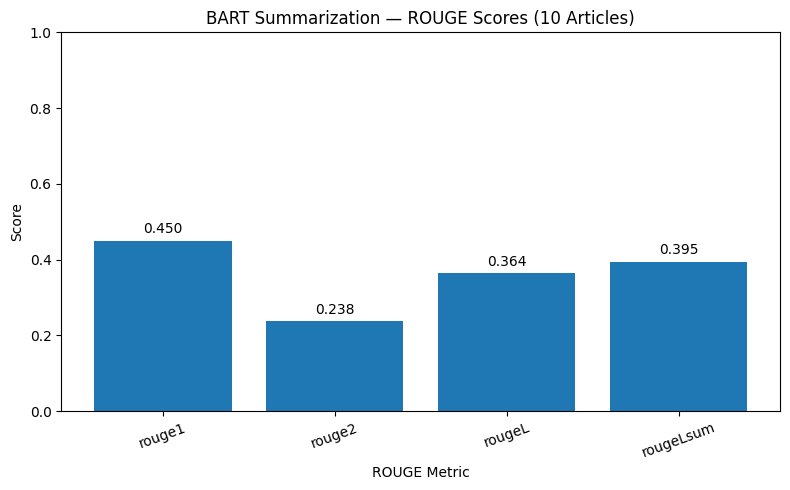

Chart saved as bart_rouge_scores.png


In [16]:

import matplotlib.pyplot as plt

metrics = list(aggregate_scores.keys())
scores = list(aggregate_scores.values())

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, scores)

plt.title("BART Summarization — ROUGE Scores (10 Articles)")
plt.xlabel("ROUGE Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("bart_rouge_scores.png", dpi=300)
plt.show()

print("Chart saved as bart_rouge_scores.png")


In [17]:

import nltk

# Download sentence-tokenization resources
nltk.download("punkt")
nltk.download("punkt_tab")

from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.text_rank import TextRankSummarizer

print("TextRank libraries loaded successfully!")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


TextRank libraries loaded successfully!


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [18]:

# Select the same article used in our earlier BART test
article = test_data[1]["article"]

# Parse the article into sentences
parser = PlaintextParser.from_string(
    article,
    Tokenizer("english")
)

# Create the TextRank summarizer
text_rank = TextRankSummarizer()

# Select the 5 most important sentences
summary_sentences = text_rank(parser.document, 5)

# Combine the sentences into a summary
textrank_summary = " ".join(
    str(sentence) for sentence in summary_sentences
)

print("TEXTRANK EXTRACTIVE SUMMARY:")
print(textrank_summary)

print("\n" + "=" * 60)
print("REFERENCE SUMMARY:")
print(test_data[1]["highlights"])


TEXTRANK EXTRACTIVE SUMMARY:
A stray pooch in Washington State has used up at least three of her own after being hit by a car, apparently whacked on the head with a hammer in a misguided mercy killing and then buried in a field -- only to survive. Four days after her apparent death, the dog managed to stagger to a nearby farm, dirt-covered and emaciated, where she was found by a worker who took her to a vet for help. The veterinary hospital's Good Samaritan Fund committee awarded some money to help pay for the dog's treatment, but Mellado has set up a fundraising page to help meet the remaining cost of the dog's care. She is dedicated to making sure Theia gets the medical attention she needs, Mellado adds, and wants to "make sure she gets placed in a family where this will never happen to her again!" A cat in Tampa, Florida, found seemingly dead after he was hit by a car in January, showed up alive in a neighbor's yard five days after he was buried by his owner.

REFERENCE SUMMARY:
The

In [19]:

# Evaluate the TextRank summary
textrank_scores = rouge.compute(
    predictions=[textrank_summary],
    references=[test_data[1]["highlights"]]
)

print("TextRank ROUGE scores:")
for metric, score in textrank_scores.items():
    print(f"{metric}: {score:.4f}")


TextRank ROUGE scores:
rouge1: 0.2743
rouge2: 0.0714
rougeL: 0.1947
rougeLsum: 0.2035


In [20]:

import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": list(textrank_scores.keys()),
    "BART": [
        aggregate_scores[metric]
        for metric in textrank_scores.keys()
    ],
    "TextRank": list(textrank_scores.values())
})

print("BART vs TextRank — ROUGE Comparison")
display(comparison_df.round(4))


BART vs TextRank — ROUGE Comparison


,Metric,BART,TextRank
0,rouge1,0.4500,0.2743
1,rouge2,0.2377,0.0714
2,rougeL,0.3644,0.1947
3,rougeLsum,0.3950,0.2035


In [21]:

textrank_results = []

for i in range(len(results_df)):
    article = test_data[i]["article"]
    reference = test_data[i]["highlights"]

    parser = PlaintextParser.from_string(
        article,
        Tokenizer("english")
    )

    # Extract the 5 most important sentences
    summary_sentences = text_rank(parser.document, 5)

    prediction = " ".join(
        str(sentence) for sentence in summary_sentences
    )

    textrank_results.append({
        "article_id": i,
        "reference_summary": reference,
        "generated_summary": prediction
    })

textrank_df = pd.DataFrame(textrank_results)

print("TextRank summaries generated:", len(textrank_df))
display(textrank_df.head(3))


TextRank summaries generated: 10


,article_id,reference_summary,generated_summary
0,0,Membership gives the ICC jurisdiction over all...,(CNN)The Palestinian Authority officially beca...
1,1,"Theia, a bully breed mix, was apparently hit b...",A stray pooch in Washington State has used up ...
2,2,Mohammad Javad Zarif has spent more time with ...,That is another way of saying that he was outs...


In [22]:

textrank_aggregate_scores = rouge.compute(
    predictions=textrank_df["generated_summary"].tolist(),
    references=textrank_df["reference_summary"].tolist()
)

print("TextRank evaluation on", len(textrank_df), "articles")
print("-" * 40)

for metric, score in textrank_aggregate_scores.items():
    print(f"{metric}: {score:.4f}")


TextRank evaluation on 10 articles
----------------------------------------
rouge1: 0.2262
rouge2: 0.0748
rougeL: 0.1586
rougeLsum: 0.1766


BART vs TextRank — 10 Articles


,Metric,BART,TextRank
0,rouge1,0.4500,0.2262
1,rouge2,0.2377,0.0748
2,rougeL,0.3644,0.1586
3,rougeLsum,0.3950,0.1766


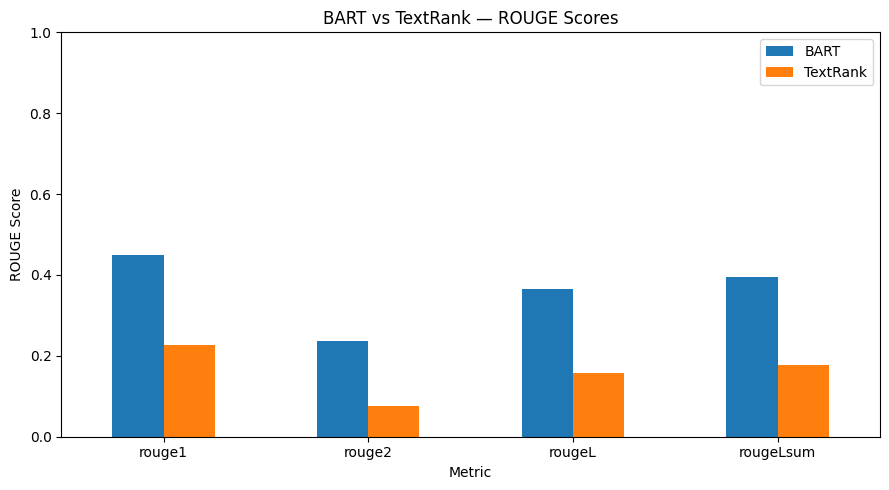

Chart saved as bart_vs_textrank_rouge.png


In [23]:

import pandas as pd
import matplotlib.pyplot as plt

comparison_df = pd.DataFrame({
    "Metric": list(aggregate_scores.keys()),
    "BART": [aggregate_scores[m] for m in aggregate_scores],
    "TextRank": [
        textrank_aggregate_scores[m]
        for m in aggregate_scores
    ]
})

print("BART vs TextRank — 10 Articles")
display(comparison_df.round(4))

# Plot both methods side by side
comparison_df.set_index("Metric")[["BART", "TextRank"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("BART vs TextRank — ROUGE Scores")
plt.ylabel("ROUGE Score")
plt.xlabel("Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("bart_vs_textrank_rouge.png", dpi=300)
plt.show()

print("Chart saved as bart_vs_textrank_rouge.png")


In [24]:

import json

# Save TextRank summaries
textrank_df.to_csv("textrank_summarization_results.csv", index=False)

# Save aggregate TextRank scores
with open("textrank_rouge_scores.json", "w") as file:
    json.dump(textrank_aggregate_scores, file, indent=4)

# Save the BART vs TextRank comparison
comparison_df.to_csv("bart_vs_textrank_comparison.csv", index=False)

print("Saved successfully:")
print("1. textrank_summarization_results.csv")
print("2. textrank_rouge_scores.json")
print("3. bart_vs_textrank_comparison.csv")


Saved successfully:
1. textrank_summarization_results.csv
2. textrank_rouge_scores.json
3. bart_vs_textrank_comparison.csv


In [25]:

import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated(0) / 1024**3, 2),
        "GB"
    )


GPU available: True
GPU: Tesla T4
GPU memory allocated: 0.0 GB


In [26]:

# Select small subsets for fine-tuning
fine_train = dataset["train"].select(range(200))
fine_valid = dataset["validation"].select(range(30))

print("Fine-tuning training examples:", len(fine_train))
print("Validation examples:", len(fine_valid))
print("Input column: article")
print("Target column: highlights")


Fine-tuning training examples: 200
Validation examples: 30
Input column: article
Target column: highlights


In [27]:

from transformers import AutoTokenizer

model_name = "facebook/bart-large-cnn"
tokenizer = AutoTokenizer.from_pretrained(model_name)

max_input_length = 512
max_target_length = 128

def preprocess_function(examples):
    # Convert news articles into input token IDs
    model_inputs = tokenizer(
        examples["article"],
        max_length=max_input_length,
        truncation=True
    )

    # Convert reference summaries into target token IDs
    labels = tokenizer(
        text_target=examples["highlights"],
        max_length=max_target_length,
        truncation=True
    )

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

print("Tokenizer loaded:", model_name)
print("Maximum article tokens:", max_input_length)
print("Maximum summary tokens:", max_target_length)


Tokenizer loaded: facebook/bart-large-cnn
Maximum article tokens: 512
Maximum summary tokens: 128


In [28]:

# Tokenize the training and validation datasets
tokenized_train = fine_train.map(
    preprocess_function,
    batched=True,
    remove_columns=fine_train.column_names
)

tokenized_valid = fine_valid.map(
    preprocess_function,
    batched=True,
    remove_columns=fine_valid.column_names
)

print("Training examples tokenized:", len(tokenized_train))
print("Validation examples tokenized:", len(tokenized_valid))
print("Tokenized columns:", tokenized_train.column_names)


Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

Training examples tokenized: 200
Validation examples tokenized: 30
Tokenized columns: ['input_ids', 'attention_mask', 'labels']


In [29]:

import torch
from transformers import AutoModelForSeq2SeqLM

model = AutoModelForSeq2SeqLM.from_pretrained(
    model_name
)

# Enable gradient checkpointing to reduce GPU memory usage
model.gradient_checkpointing_enable()

# Check that the model is loaded
print("Model loaded:", model.config._name_or_path)
print("Model type:", model.config.model_type)
print("GPU available:", torch.cuda.is_available())
print("Gradient checkpointing enabled.")


Model loaded: facebook/bart-large-cnn
Model type: bart
GPU available: True
Gradient checkpointing enabled.


In [30]:

from transformers import (
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq
)

training_args = Seq2SeqTrainingArguments(
    output_dir="./bart-cnn-finetuned",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    weight_decay=0.01,
    predict_with_generate=False,
    fp16=torch.cuda.is_available(),
    gradient_checkpointing=True,
    logging_steps=20,
    save_total_limit=1,
    report_to="none",
    seed=42
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model
)

print("Training configuration created successfully.")
print("Epochs:", training_args.num_train_epochs)
print("Training batch size:", training_args.per_device_train_batch_size)
print("Gradient accumulation steps:", training_args.gradient_accumulation_steps)


Training configuration created successfully.
Epochs: 1
Training batch size: 1
Gradient accumulation steps: 4


In [31]:

from transformers import Seq2SeqTrainer

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_valid,
    processing_class=tokenizer,
    data_collator=data_collator
)

print("Trainer created successfully!")
print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_valid))


Trainer created successfully!
Training examples: 200
Validation examples: 30


In [32]:

if "trainer" in globals():
    print("Trainer exists:", type(trainer).__name__)
    print("Training examples:", len(trainer.train_dataset))
    print("Validation examples:", len(trainer.eval_dataset))
else:
    print("Trainer has not been created yet.")


Trainer exists: Seq2SeqTrainer
Training examples: 200
Validation examples: 30


In [33]:

# Start fine-tuning
train_result = trainer.train()

print("\nFine-tuning completed!")
print("Training metrics:")
print(train_result.metrics)


Epoch,Training Loss,Validation Loss
1,1.696300,1.597749


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:2758: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 142, 'min_length': 56, 'early_stopping': True, 'num_beams': 4, 'length_penalty': 2.0, 'no_repeat_ngram_size': 3, 'forced_bos_token_id': 0}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(



Fine-tuning completed!
Training metrics:
{'train_runtime': 174.2461, 'train_samples_per_second': 1.148, 'train_steps_per_second': 0.287, 'total_flos': 199297436123136.0, 'train_loss': 1.8911236381530763, 'epoch': 1.0}


In [34]:

# Display the final training metrics
print("Training metrics:")
print(train_result.metrics)

# Check the Trainer's training step count
print("\nGlobal training steps:", trainer.state.global_step)
print("Completed epochs:", trainer.state.epoch)


Training metrics:
{'train_runtime': 174.2461, 'train_samples_per_second': 1.148, 'train_steps_per_second': 0.287, 'total_flos': 199297436123136.0, 'train_loss': 1.8911236381530763, 'epoch': 1.0}

Global training steps: 50
Completed epochs: 1.0


In [35]:

import json
import os

save_directory = "./bart-cnn-finetuned-final"

# Save model and tokenizer
trainer.save_model(save_directory)
tokenizer.save_pretrained(save_directory)

# Save training metrics
with open(
    os.path.join(save_directory, "training_metrics.json"),
    "w"
) as file:
    json.dump(train_result.metrics, file, indent=4)

print("Fine-tuned model and tokenizer saved to:", save_directory)


Fine-tuned model and tokenizer saved to: ./bart-cnn-finetuned-final


In [36]:

import json
import os

save_directory = "./bart-cnn-finetuned-final"

# Save the model and tokenizer
trainer.save_model(save_directory)
tokenizer.save_pretrained(save_directory)

# Save the training metrics
with open(
    os.path.join(save_directory, "training_metrics.json"),
    "w"
) as file:
    json.dump(train_result.metrics, file, indent=4)

print("Fine-tuned model and tokenizer saved to:", save_directory)
print("Training metrics saved successfully.")


Fine-tuned model and tokenizer saved to: ./bart-cnn-finetuned-final
Training metrics saved successfully.


In [37]:

from transformers import AutoModelForSeq2SeqLM
import torch
import pandas as pd
from tqdm.auto import tqdm

# Load the saved fine-tuned model
fine_tuned_model = AutoModelForSeq2SeqLM.from_pretrained(
    "./bart-cnn-finetuned-final"
)

fine_tuned_model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
fine_tuned_model.to(device)

print("Fine-tuned model loaded on:", device)


/usr/local/lib/python3.13/dist-packages/transformers/models/bart/configuration_bart.py:176: UserWarning: Please make sure the config includes `forced_bos_token_id=0` in future versions. The config can simply be saved and uploaded again to be fixed.
  warnings.warn(


Fine-tuned model loaded on: cuda


In [38]:

fine_tuned_results = []

for i in tqdm(range(len(results_df))):
    article = test_data[i]["article"]
    reference = test_data[i]["highlights"]

    inputs = tokenizer(
        article,
        max_length=512,
        truncation=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        output_ids = fine_tuned_model.generate(
            **inputs,
            max_new_tokens=100,
            min_new_tokens=25,
            num_beams=2,
            do_sample=False
        )

    prediction = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    fine_tuned_results.append({
        "article_id": i,
        "reference_summary": reference,
        "generated_summary": prediction
    })

fine_tuned_df = pd.DataFrame(fine_tuned_results)

print("Fine-tuned summaries generated:", len(fine_tuned_df))
display(fine_tuned_df.head(3))


  0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1528: UserWarning: You have modified the pretrained model configuration to control generation. This is a deprecated strategy to control generation and will be removed in v5. Please use and modify the model generation configuration (see https://huggingface.co/docs/transformers/generation_strategies#default-text-generation-configuration )
  warnings.warn(


Fine-tuned summaries generated: 10


,article_id,reference_summary,generated_summary
0,0,Membership gives the ICC jurisdiction over all...,
1,1,"Theia, a bully breed mix, was apparently hit b...",
2,2,Mohammad Javad Zarif has spent more time with ...,. . . . .Zarif is the Iranian foreign ministe...


In [39]:

fine_tuned_scores = rouge.compute(
    predictions=fine_tuned_df["generated_summary"].tolist(),
    references=fine_tuned_df["reference_summary"].tolist()
)

print("Fine-tuned BART — ROUGE results")
print("-" * 40)

for metric, score in fine_tuned_scores.items():
    print(f"{metric}: {score:.4f}")


Fine-tuned BART — ROUGE results
----------------------------------------
rouge1: 0.1486
rouge2: 0.0638
rougeL: 0.1015
rougeLsum: 0.1329


Final ROUGE Comparison — 10 Test Articles


,Metric,Original BART,Fine-tuned BART,TextRank
0,rouge1,0.4500,0.1486,0.2262
1,rouge2,0.2377,0.0638,0.0748
2,rougeL,0.3644,0.1015,0.1586
3,rougeLsum,0.3950,0.1329,0.1766


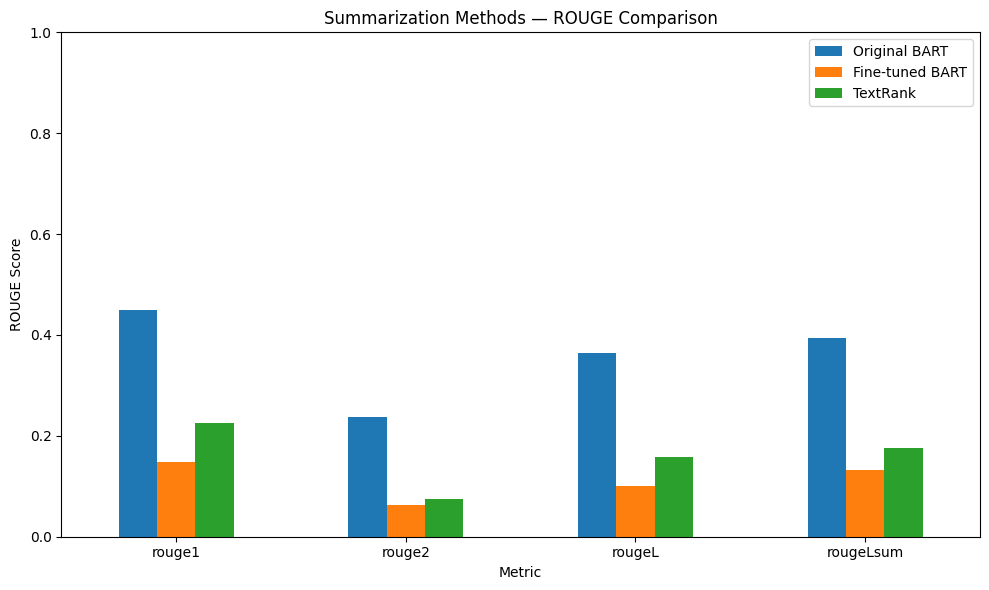

Saved final_summarization_comparison.png
Saved final_summarization_comparison.csv


In [40]:

import pandas as pd
import matplotlib.pyplot as plt

final_comparison = pd.DataFrame({
    "Metric": list(aggregate_scores.keys()),
    "Original BART": [
        aggregate_scores[m] for m in aggregate_scores
    ],
    "Fine-tuned BART": [
        fine_tuned_scores[m] for m in aggregate_scores
    ],
    "TextRank": [
        textrank_aggregate_scores[m] for m in aggregate_scores
    ]
})

print("Final ROUGE Comparison — 10 Test Articles")
display(final_comparison.round(4))

# Create a comparison chart
final_comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Summarization Methods — ROUGE Comparison")
plt.ylabel("ROUGE Score")
plt.xlabel("Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("final_summarization_comparison.png", dpi=300)
plt.show()

# Save the comparison table
final_comparison.to_csv(
    "final_summarization_comparison.csv",
    index=False
)

print("Saved final_summarization_comparison.png")
print("Saved final_summarization_comparison.csv")


In [41]:

import os

files_to_check = [
    "bart_summarization_results.csv",
    "bart_rouge_scores.json",
    "bart_rouge_scores.png",
    "textrank_summarization_results.csv",
    "textrank_rouge_scores.json",
    "bart_vs_textrank_comparison.csv",
    "bart_vs_textrank_rouge.png",
    "final_summarization_comparison.csv",
    "final_summarization_comparison.png"
]

print("Project output file check:")
print("-" * 40)

for filename in files_to_check:
    print(
        ("FOUND  " if os.path.exists(filename) else "MISSING "),
        filename
    )

print(
    "\nFine-tuned model folder exists:",
    os.path.isdir("./bart-cnn-finetuned-final")
)


Project output file check:
----------------------------------------
FOUND   bart_summarization_results.csv
FOUND   bart_rouge_scores.json
FOUND   bart_rouge_scores.png
FOUND   textrank_summarization_results.csv
FOUND   textrank_rouge_scores.json
FOUND   bart_vs_textrank_comparison.csv
FOUND   bart_vs_textrank_rouge.png
FOUND   final_summarization_comparison.csv
FOUND   final_summarization_comparison.png

Fine-tuned model folder exists: True


In [42]:

import os
import shutil

project_dir = "text-summarization-transformers"
os.makedirs(project_dir, exist_ok=True)

# Copy experiment outputs into the project folder
files_to_copy = [
    "bart_summarization_results.csv",
    "bart_rouge_scores.json",
    "bart_rouge_scores.png",
    "textrank_summarization_results.csv",
    "textrank_rouge_scores.json",
    "bart_vs_textrank_comparison.csv",
    "bart_vs_textrank_rouge.png",
    "final_summarization_comparison.csv",
    "final_summarization_comparison.png"
]

for filename in files_to_copy:
    shutil.copy2(filename, os.path.join(project_dir, filename))

# Copy the fine-tuned model directory
model_source = "./bart-cnn-finetuned-final"
model_destination = os.path.join(project_dir, "bart-cnn-finetuned-final")

if os.path.exists(model_destination):
    shutil.rmtree(model_destination)

shutil.copytree(model_source, model_destination)

print("Project folder created:", project_dir)
print("Output files copied:", len(files_to_copy))
print("Fine-tuned model copied:", os.path.exists(model_destination))


Project folder created: text-summarization-transformers
Output files copied: 9
Fine-tuned model copied: True


In [45]:

requirements_content = """\
torch
transformers==4.48.3
tokenizers==0.21.0
datasets
evaluate
rouge_score
nltk
sumy
pandas
matplotlib
accelerate
"""

requirements_path = os.path.join(project_dir, "requirements.txt")

with open(requirements_path, "w", encoding="utf-8") as file:
    file.write(requirements_content)

print("Created:", requirements_path)
print("\nRequirements:")
print(requirements_content)


Created: text-summarization-transformers/requirements.txt

Requirements:
torch
transformers==4.48.3
tokenizers==0.21.0
datasets
evaluate
rouge_score
nltk
sumy
pandas
matplotlib
accelerate



In [52]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "text-summarization-transformers",
    "zip",
    root_dir=project_dir
)

print("ZIP created:", zip_path)
files.download(zip_path)


ZIP created: /content/text-summarization-transformers.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>